# 02 · Benchmark
Macro-F1 per model and dataset (`metrics.json`), and the ensemble's confusion matrices (`confusions/`). OOF columns are scenario-held-out over the frozen folds; our_test is our own test set.

In [1]:
import json
from pathlib import Path

import pandas as pd

R = Path("../reports")  # the only directory read (scripts/run_notebooks.py --check-reads-only)


def load(name):
    return json.loads((R / name).read_text(encoding="utf-8"))
m = load("metrics.json")
b = pd.DataFrame(m["benchmark"])
for target in ("category", "priority"):
    t = b[b.target == target].pivot(index="model", columns="dataset", values="macro_f1")
    display(t.round(3).fillna("-"))

dataset,oof_all,oof_official,our_test,our_test_set1,our_test_set2,our_test_set3,our_test_set4
model,,,,,,,
Ensemble (tier 0),0.935,0.935,0.769,0.8,0.828,0.731,0.751
Ensemble + router,-,-,-,-,-,-,-
LLM zero-shot (M4),-,-,-,-,-,-,-
M1,0.205,0.205,0.562,0.586,0.56,0.54,0.547
M2-LR,0.613,0.613,0.766,0.668,0.774,0.778,0.788
M2-kNN,0.464,0.464,0.634,0.663,0.597,0.598,0.651
M2-proto,0.935,0.935,0.767,0.8,0.815,0.731,0.751
M3,-,-,-,-,-,-,-


dataset,oof_all,oof_official,our_test,our_test_set1,our_test_set2,our_test_set3,our_test_set4
model,,,,,,,
Ensemble (tier 0),0.904,0.904,0.752,0.782,0.809,0.793,0.676
Ensemble + router,-,-,-,-,-,-,-
LLM zero-shot (M4),-,-,-,-,-,-,-
M1,0.542,0.542,0.481,0.638,0.43,0.465,0.437
M2-LR,0.651,0.651,0.592,0.665,0.606,0.581,0.511
M2-kNN,0.396,0.396,0.396,0.605,0.414,0.363,0.271
M2-proto,-,-,-,-,-,-,-
M3,-,-,-,-,-,-,-


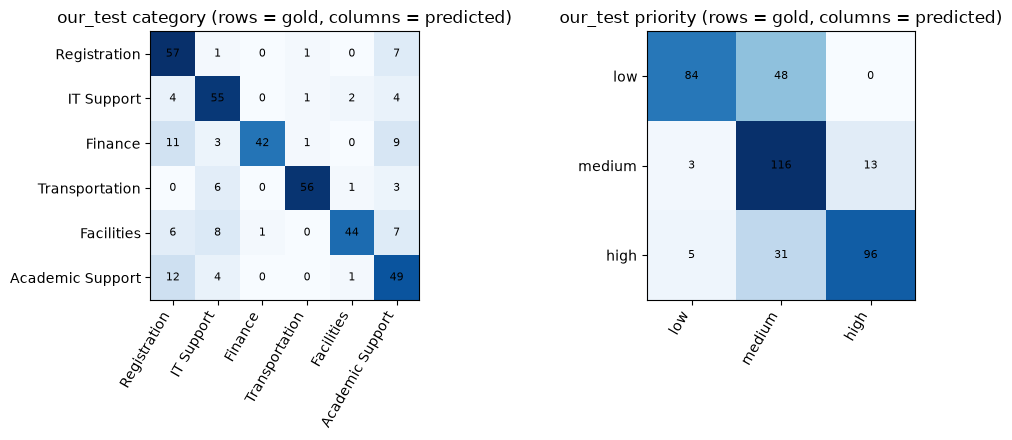

In [2]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, target in zip(axes, ("category", "priority"), strict=True):
    c = load(f"confusions/ensemble_{target}_our_test.json")
    mat = np.array(c["matrix"])
    ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(len(c["labels"])), c["labels"], rotation=60, ha="right")
    ax.set_yticks(range(len(c["labels"])), c["labels"])
    for i in range(len(mat)):
        for j in range(len(mat)):
            ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=8)
    ax.set_title(f"our_test {target} (rows = gold, columns = predicted)")
plt.tight_layout()
plt.show()

## Default mode: our model with the LLM (G)
Everything above is the **offline** model: `evaluate.py` runs it with no key and no network, so anyone can reproduce it. The submitted `predict.py` runs, by default, an LLM front end (Arabic and Arabizi translated to English) and a set-constrained tie-breaker (category chosen from the model's top three, priority re-judged; a rule-set `high` is never lowered). `scripts/score_llm_mode.py` scores those saved predictions (`reports/llm_mode/`) on the same test sets. Macro-F1 with a 95% bootstrap interval.

In [3]:
g = load("llm_mode.json")
print("LLM:", g["llm_model"])
s = pd.DataFrame(g["scores"])
offline = b[b.model == "Ensemble (tier 0)"].set_index(["dataset", "target"])["macro_f1"]
overall = s[s.lang == "all"].copy()
overall["offline"] = [offline.get((d, t)) for d, t in zip(overall.dataset, overall.target, strict=True)]
overall["with LLM (95% CI)"] = [
    f"{f:.3f} ({lo:.2f}-{hi:.2f})"
    for f, lo, hi in zip(overall.macro_f1, overall.ci_low, overall.ci_high, strict=True)
]
display(overall.pivot(index="dataset", columns="target", values=["offline", "with LLM (95% CI)"])
        .round(3).fillna("-"))
per_lang = s[(s.dataset == "our_test") & (s.lang != "all")]
display(per_lang.pivot(index="lang", columns="target", values="macro_f1").round(3))

LLM: deepseek/deepseek-v4.1-flash


offline           with LLM (95% CI)                   
target        category priority           category           priority
dataset                                                              
our_test        0.7691   0.7521  0.960 (0.94-0.98)  0.972 (0.95-0.99)
our_test_set1   0.7999   0.7825  1.000 (1.00-1.00)  1.000 (1.00-1.00)
our_test_set2   0.8283   0.8086  0.972 (0.92-1.00)  0.972 (0.93-1.00)
our_test_set3   0.7314   0.7929  0.963 (0.92-0.99)  0.954 (0.91-0.99)
our_test_set4   0.7514   0.6759  0.932 (0.88-0.97)  0.972 (0.94-1.00)
validation           -        -  1.000 (1.00-1.00)  1.000 (1.00-1.00)

target,category,priority
lang,,
ar,0.970,0.952
arabizi,0.942,0.944
en,0.960,0.994


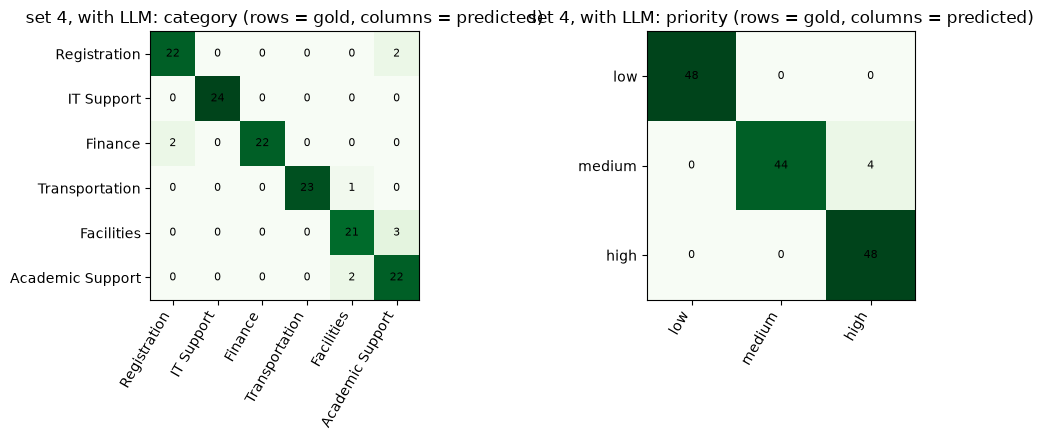

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, target in zip(axes, ("category", "priority"), strict=True):
    c = g["confusions"][f"{target}_our_test_set4"]
    mat = np.array(c["matrix"])
    ax.imshow(mat, cmap="Greens")
    ax.set_xticks(range(len(c["labels"])), c["labels"], rotation=60, ha="right")
    ax.set_yticks(range(len(c["labels"])), c["labels"])
    for i in range(len(mat)):
        for j in range(len(mat)):
            ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=8)
    ax.set_title(f"set 4, with LLM: {target} (rows = gold, columns = predicted)")
plt.tight_layout()
plt.show()